In [144]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Settings for prettier plots (optional)
import warnings
warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
plt.style.use('ggplot')

In [145]:
file_path = '/Users/anand/Documents/Datasets/adult.csv'
df = pd.read_csv(file_path, header = None)
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [146]:
import pandas as pd

# Load the dataset with tab separation
df = pd.read_csv(file_path, header = None)
# Add column names
df.columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
    'income'
] 
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


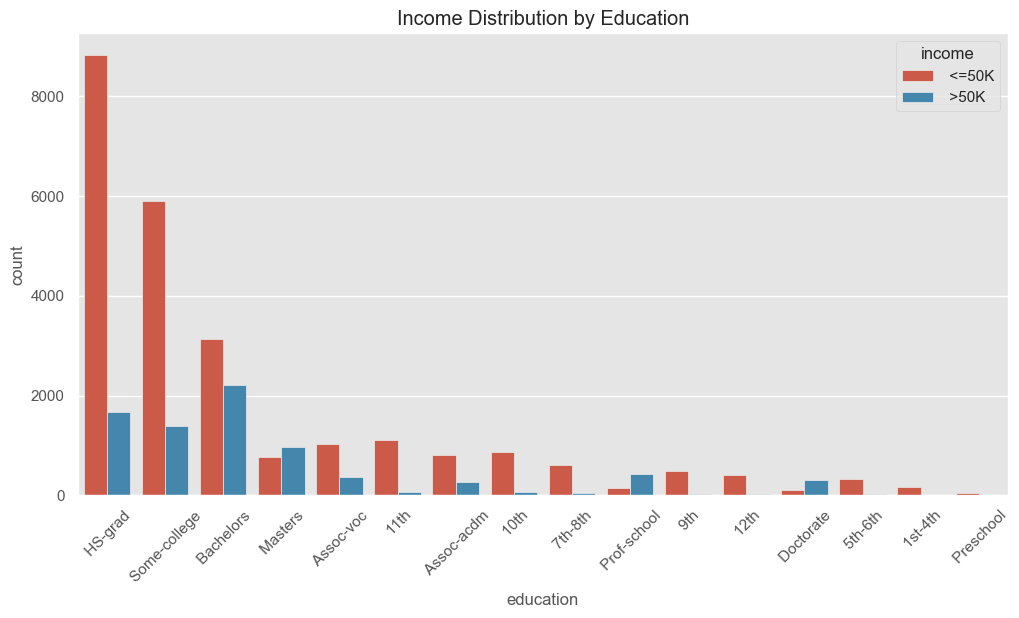

In [147]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='education', hue='income', order=df['education'].value_counts().index)
plt.xticks(rotation=45)
plt.title("Income Distribution by Education")
plt.show()

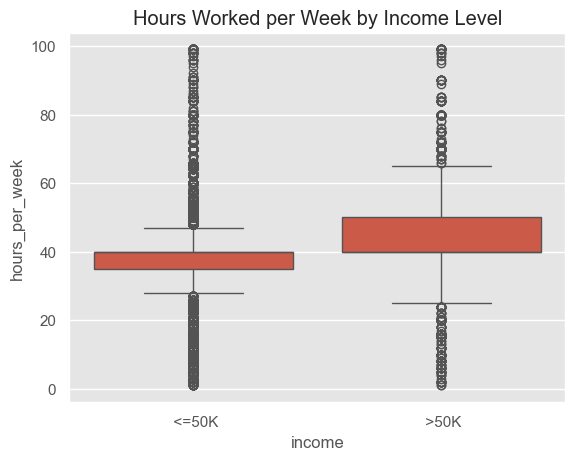

In [148]:
sns.boxplot(data=df, x='income', y='hours_per_week')
plt.title("Hours Worked per Week by Income Level")
plt.show()

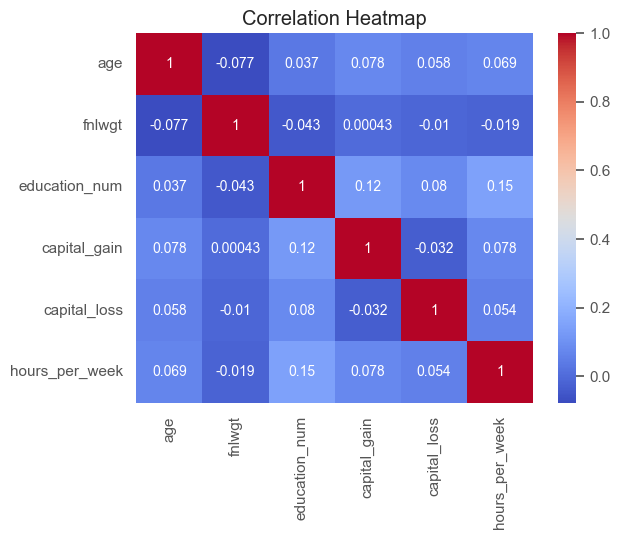

In [149]:
numerics = df.select_dtypes(include='number')
sns.heatmap(numerics.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [150]:
print(df['income'].value_counts(normalize=True))


income
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64


In [151]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define column names (based on dataset structure)
columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
    'income'
]


# Encode categorical features
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col])

# Split features and target
X = df.drop('income', axis=1)
y = df['income']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [152]:
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [153]:
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8719484108705665
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      4942
           1       0.77      0.68      0.72      1571

    accuracy                           0.87      6513
   macro avg       0.83      0.80      0.82      6513
weighted avg       0.87      0.87      0.87      6513



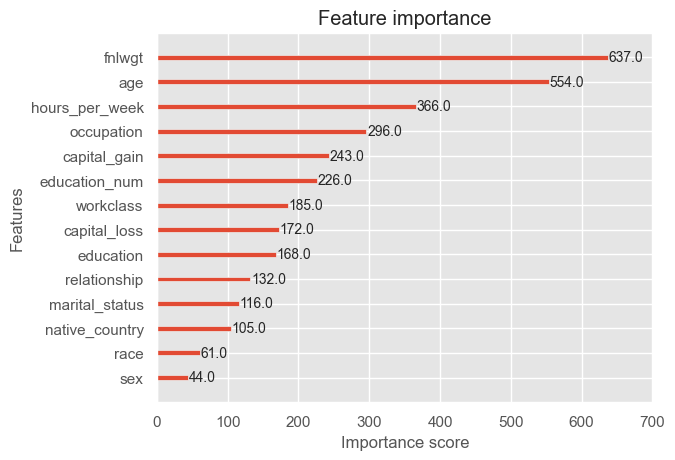

In [154]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

plot_importance(model)
plt.show()


In [155]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [156]:
# Generate synthetic data
X = np.array([[1], [2], [3], [4], [5]])  # Input feature
y = np.array([2, 4, 5, 4, 5])            # Target variable

In [157]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


In [158]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [159]:
y_pred = model.predict(X_test)
print("Predictions:", y_pred)

Predictions: [3.75]


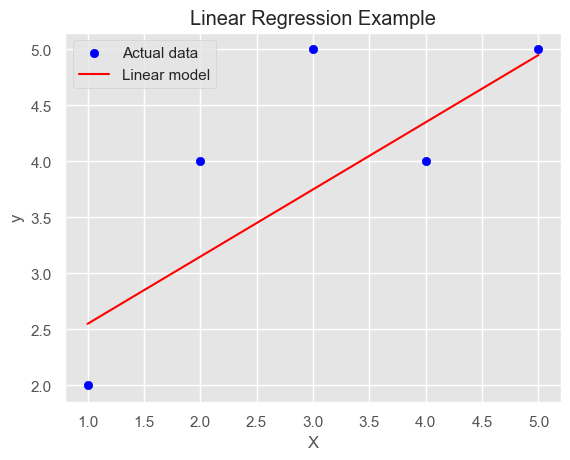

In [160]:
plt.scatter(X, y, color='blue', label='Actual data')
plt.plot(X, model.predict(X), color='red', label='Linear model')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression Example')
plt.legend()
plt.show()

In [161]:
print("Slope (coefficient):", model.coef_)
print("Intercept:", model.intercept_)
print(df.columns.tolist())


Slope (coefficient): [0.6]
Intercept: 1.9500000000000002
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


In [162]:
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

df = pd.read_csv(file_path, header=None, names=column_names)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Define column names since the dataset has no header row
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Load the dataset without a header
df = pd.read_csv(file_path, header=None, names=column_names)

# Drop any rows with missing target
df = df.dropna(subset=['income'])

# Create binary target variable
y = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)

# Drop target column to get features
X = df.drop('income', axis=1)

# Identify categorical and numeric columns
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessors
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# Full modeling pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Hyperparameter grid for tuning
param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5]
}

# Inner and outer cross-validation strategies
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# GridSearchCV inside cross_val_score = nested CV
clf = GridSearchCV(pipeline, param_grid=param_grid, cv=inner_cv)

# Perform nested cross-validation
nested_scores = cross_val_score(clf, X, y, cv=outer_cv)

# Output results
print("Nested CV accuracy scores:", nested_scores)
print("Mean accuracy: {:.3f}".format(np.mean(nested_scores)))

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

file_path = '/Users/anand/Documents/Datasets/adult.csv' 

# Define column names (Adult dataset)
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Load CSV without a header
df = pd.read_csv(file_path, header=None, names=column_names)

# Drop any rows with missing target
df = df.dropna(subset=['income'])

# Binary target
y = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
X = df.drop('income', axis=1)

# # Identify categorical and numeric columns
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

# # Preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# # Full modeling pipeline with XGBoost
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        use_label_encoder=False,
        random_state=42
    ))
])

# # Expanded hyperparameter search space for XGBoost
param_dist = {
    'classifier__n_estimators': [100],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.3],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'classifier__gamma': [0, 1, 5],
    'classifier__reg_lambda': [0.1, 1, 10],
    'classifier__reg_alpha': [0, 0.1, 1]
}

# # Inner and outer CV
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# # RandomizedSearchCV for XGBoost
clf = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=20,                 # Number of random combinations to try
    cv=inner_cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=2,                 # Use all CPU cores
    verbose=1
)

print("Running nested cross-validation... please wait.")
nested_scores = cross_val_score(clf, X, y, cv=outer_cv, n_jobs=5)

print("Nested CV accuracy scores:", nested_scores)
print("Mean accuracy: {:.3f}".format(np.mean(nested_scores)))

Running nested cross-validation... please wait.


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 2 is smaller than n_iter=20. Running 2 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 2 is smaller than n_iter=20. Running 2 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 2 is smaller than n_iter=20. Running 2 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 2 is smaller th

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 2 candidates, totalling 6 fits


In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

file_path = '/Users/anand/Documents/Datasets/adult.csv' 

# Define column names (Adult dataset)
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Load CSV without a header
df = pd.read_csv(file_path, header=None, names=column_names)

# Drop any rows with missing target
df = df.dropna(subset=['income'])

# Binary target
y = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
X = df.drop('income', axis=1)

# Identify categorical and numeric columns
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# ✅ Step 1: Preprocess the entire dataset first
X_processed = preprocessor.fit_transform(X)

# Convert to numpy array (scipy sparse if many categories, so ensure dense if needed)
X_processed = X_processed.toarray() if hasattr(X_processed, "toarray") else X_processed

# ✅ Step 2: Define classifier (no preprocessing inside pipeline anymore)
classifier = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

# Reduced hyperparameter search space for speed
param_dist = {
    'n_estimators': [100],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 1],
    'reg_lambda': [1, 10],
    'reg_alpha': [0, 0.1]
}

# ✅ Inner and outer CV (reduced folds for faster runtime)
inner_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)

# RandomizedSearchCV for XGBoost
clf = RandomizedSearchCV(
    classifier,
    param_distributions=param_dist,
    n_iter=10,                 # fewer random combinations
    cv=inner_cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=2,
    verbose=1
)

print("Running nested cross-validation... please wait.")
nested_scores = cross_val_score(clf, X_processed, y, cv=outer_cv, n_jobs=5)

print("Nested CV accuracy scores:", nested_scores)
print("Mean accuracy: {:.3f}".format(np.mean(nested_scores)))


Running nested cross-validation... please wait.


[12:06:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[12:06:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.
[12:06:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.


[12:06:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[12:06:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[12:06:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[12:06:36] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[12:06:36] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" }

Nested CV accuracy scores: [0.87295006 0.87442418 0.86750207]
Mean accuracy: 0.872
Fitting 2 folds for each of 10 candidates, totalling 20 fits
Fitting 2 folds for each of 10 candidates, totalling 20 fits
Fitting 2 folds for each of 10 candidates, totalling 20 fits


In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

file_path = '/Users/anand/Documents/Datasets/adult.csv' 

# Define column names (Adult dataset)
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Load CSV without a header
df = pd.read_csv(file_path, header=None, names=column_names)

# Drop any rows with missing target
df = df.dropna(subset=['income'])

# Binary target
y = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
X = df.drop('income', axis=1)

# Identify categorical and numeric columns
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# ✅ Step 1: Preprocess the entire dataset first
X_processed = preprocessor.fit_transform(X)
X_processed = X_processed.toarray() if hasattr(X_processed, "toarray") else X_processed

# ✅ Step 2: Define classifier
classifier = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

# Expanded hyperparameter search space
param_dist = {
    'n_estimators': [100, 200, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 1],
    'reg_lambda': [1, 10],
    'reg_alpha': [0, 0.1]
}

# ✅ Inner and outer CV (now 5 folds each, more standard)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# RandomizedSearchCV for XGBoost
clf = RandomizedSearchCV(
    classifier,
    param_distributions=param_dist,
    n_iter=20,                 # increase back up since search space is larger
    cv=inner_cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=2,
    verbose=1
)

print("Running nested cross-validation... please wait.")
nested_scores = cross_val_score(clf, X_processed, y, cv=outer_cv, n_jobs=5)

print("Nested CV accuracy scores:", nested_scores)
print("Mean accuracy: {:.3f}".format(np.mean(nested_scores)))

# ✅ Fit once on full dataset to extract best parameters
clf.fit(X_processed, y)
print("Best hyperparameters found:", clf.best_params_)


Running nested cross-validation... please wait.


[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[20:38:59] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" }

Nested CV accuracy scores: [0.87164133 0.88098894 0.87561425 0.87070025 0.86839681]
Mean accuracy: 0.873
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [20:42:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [20:42:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [20:42:12] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [20:42:12] WARN

Best hyperparameters found: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}


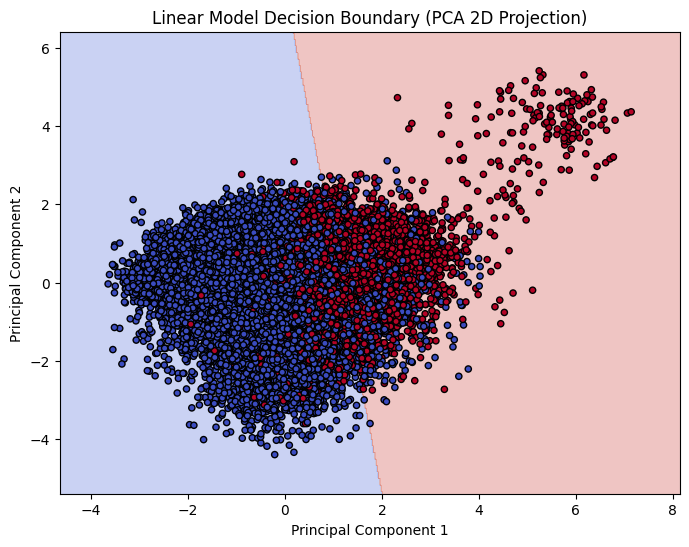

In [24]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

# ✅ Step 1: Fit a simple linear model
linear_model = LogisticRegression(max_iter=1000, random_state=42)
linear_model.fit(X_processed, y)

# ✅ Step 2: Reduce to 2D with PCA for visualization
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_processed)

# Refit linear model on reduced 2D data for visualization purposes
linear_model_2d = LogisticRegression(max_iter=1000, random_state=42)
linear_model_2d.fit(X_2d, y)

# ✅ Step 3: Create decision boundary grid
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

Z = linear_model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# ✅ Step 4: Plot
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolor='k', s=20)
plt.title("Linear Model Decision Boundary (PCA 2D Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# ===========================================
# Load dataset
# ===========================================
file_path = '/Users/anand/Documents/Datasets/adult.csv'

column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

df = pd.read_csv(file_path, header=None, names=column_names)
df = df.dropna(subset=['income'])

y = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
X = df.drop('income', axis=1)

# ===========================================
# Preprocessing
# ===========================================
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

X_processed = preprocessor.fit_transform(X)
X_processed = X_processed.toarray() if hasattr(X_processed, "toarray") else X_processed

# ===========================================
# 1. Logistic Regression (3-fold CV for speed)
# ===========================================
log_reg = LogisticRegression(max_iter=1000, random_state=42)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
log_reg_scores = cross_val_score(log_reg, X_processed, y, cv=cv, scoring='accuracy', n_jobs=5)

# ===========================================
# 2. XGBoost with Nested CV (2x3 folds for speed)
# ===========================================
classifier = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

param_dist = {
    'n_estimators': [100, 200, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 1],
    'reg_lambda': [1, 10],
    'reg_alpha': [0, 0.1]
}

inner_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)

clf = RandomizedSearchCV(
    classifier,
    param_distributions=param_dist,
    n_iter=10,  # smaller for speed
    cv=inner_cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=2,
    verbose=1
)

nested_scores = cross_val_score(clf, X_processed, y, cv=outer_cv, n_jobs=3)

# ===========================================
# Results
# ===========================================
print("\n===== Model Comparison =====")
print("Logistic Regression CV Accuracy: {:.3f} ± {:.3f}".format(log_reg_scores.mean(), log_reg_scores.std()))
print("XGBoost Nested CV Accuracy: {:.3f} ± {:.3f}".format(nested_scores.mean(), nested_scores.std()))


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits

===== Model Comparison =====
Logistic Regression CV Accuracy: 0.852 ± 0.003
XGBoost Nested CV Accuracy: 0.872 ± 0.004
Fitting 2 folds for each of 10 candidates, totalling 20 fits
Fitting 2 folds for each of 10 candidates, totalling 20 fits
Fitting 2 folds for each of 10 candidates, totalling 20 fits


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

# ===========================================
# Load dataset
# ===========================================
file_path = '/Users/anand/Documents/Datasets/adult.csv' 

column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

df = pd.read_csv(file_path, header=None, names=column_names)
df = df.dropna(subset=['income'])

y = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
X = df.drop('income', axis=1)

# ===========================================
# Preprocessing
# ===========================================
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# ===========================================
# XGBoost pipeline
# ===========================================
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42
    ))
])

param_dist = {
    'classifier__n_estimators': [100],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.3],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'classifier__gamma': [0, 1, 5],
    'classifier__reg_lambda': [0.1, 1, 10],
    'classifier__reg_alpha': [0, 0.1, 1]
}

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

clf = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=inner_cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=2,
    verbose=1
)

print("Running nested cross-validation with XGBoost... please wait.")
nested_scores = cross_val_score(clf, X, y, cv=outer_cv, n_jobs=5)

print("\n===== XGBoost Results =====")
print("Nested CV accuracy scores:", nested_scores)
print("Mean accuracy: {:.3f}".format(np.mean(nested_scores)))

# ===========================================
# PyTorch Quickstart
# ===========================================
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

print("\n===== PyTorch Quickstart =====")
# Tensor basics
a = torch.tensor([1, 2, 3])
b = torch.tensor([4, 5, 6])
print("Tensor a:", a)
print("Tensor b:", b)
print("a + b:", a + b)
print("a * b:", a * b)

# ===========================================
# PyTorch model on the Adult dataset
# ===========================================
print("\nTraining a simple PyTorch model...")

# Preprocess dataset (numeric only for quick demo)
X_proc = preprocessor.fit_transform(X)
X_proc = X_proc.toarray() if hasattr(X_proc, "toarray") else X_proc

X_train, X_test, y_train, y_test = train_test_split(
    X_proc, y, test_size=0.2, random_state=42, stratify=y
)

# Convert to tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

train_data = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

# Define simple neural net
class SimpleNN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.sigmoid(self.fc3(x))
        return x

model = SimpleNN(X_train.shape[1])
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
for epoch in range(3):  # keep epochs small for speed
    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

# Evaluate
with torch.no_grad():
    preds = model(X_test_tensor)
    preds_class = (preds > 0.5).float()
    accuracy = (preds_class.eq(y_test_tensor).sum() / len(y_test_tensor)).item()

print("\n===== PyTorch Results =====")
print("Test Accuracy: {:.3f}".format(accuracy))


ModuleNotFoundError: No module named 'pandas'

In [2]:
import sys 

In [3]:
!{sys.executable} -m pip install torch

ERROR: Could not find a version that satisfies the requirement torch (from versions: none)
ERROR: No matching distribution found for torch


In [4]:
!{sys.executable} --version

Python 3.13.1


In [2]:
import torch 